# 00 - What is in this package?

Open a real EnergyML package and find your way around it: what it holds, what points at
what, an object, its arrays, its geometry. It runs on **Lutetia**, a synthetic model (CC BY 4.0) built on boreholes of the BRGM Banque du sous-sol (Licence Ouverte 2.0), modified for the example: [geosiris-technologies/energyml-lutetia](https://github.com/geosiris-technologies/energyml-lutetia). The first run downloads it (27 MB) at the commit this repository pins; see `_lutetia.py`.

```
pip install energyml-rust matplotlib pandas
```

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energyml.rust.epc import Epc
from energyml.rust.resqml import geometry_of

from _lutetia import lutetia

root = lutetia()

## Opening

`Epc.open` reads the package's index, not its objects: an object is parsed when it is asked
for. `objects()` lists what is there as `Summary` rows - uri, uuid, qualified type, title.

In [2]:
pkg = Epc.open(str(root / "package" / "Lutetia.epc"))
objects = pkg.objects()
print(f"{len(objects)} objects")
objects[:3]

1303 objects


[Summary(eml23.Activity "contacts-from-frames → 1 point set(s)"),
 Summary(resqml22.StructuralOrganizationInterpretation "Lutetia - scenario A, ordered and dated"),
 Summary(resqml22.ContinuousProperty "BSS000NUKM - pressure")]

The **uri** is the object's identity, and every other call takes it. The qualified type
says the standard and its version: `resqml22` is RESQML 2.2, `eml23` the common EML 2.3 that
RESQML 2.2, WITSML 2.1 and PRODML 2.3 share.

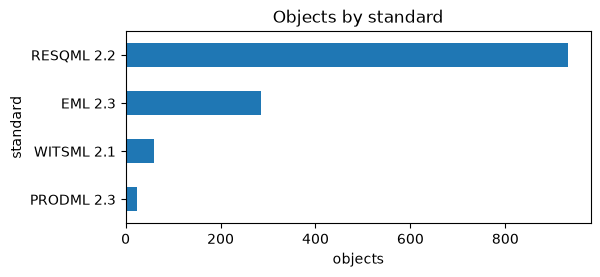

objects
standard   class                                          
RESQML 2.2 DiscreteProperty                            449
EML 2.3    Activity                                    106
RESQML 2.2 ContinuousProperty                           69
           RockVolumeFeature                            53
           StratigraphicUnitInterpretation              53
EML 2.3    ActivityTemplate                             48
           DataobjectCollection                         47
RESQML 2.2 WellboreTrajectoryRepresentation             44
           WellboreFrameRepresentation                  44
           BoundaryFeature                              41
           HorizonInterpretation                        38
EML 2.3    CollectionsToDataobjectsAssociationSet       30

In [3]:
NAMES = {"resqml": "RESQML", "witsml": "WITSML", "prodml": "PRODML", "eml": "EML"}


def standard(qualified_type: str) -> str:
    prefix = qualified_type.split(".", 1)[0]  # resqml22, eml23, witsml21...
    name = prefix.rstrip("0123456789")
    digits = prefix[len(name):]
    return f"{NAMES.get(name, name)} {digits[0]}.{digits[1:]}"


table = pd.DataFrame(
    {"standard": standard(o.qualified_type), "class": o.qualified_type.split(".", 1)[1], "title": o.title}
    for o in objects
)
ax = table["standard"].value_counts().sort_values().plot.barh(figsize=(6, 2.5), title="Objects by standard")
ax.set_xlabel("objects")
plt.show()
table.groupby(["standard", "class"]).size().sort_values(ascending=False).head(12).to_frame("objects")

## Finding objects

`find(of_type, titled)` filters by type and by a piece of the title, case ignored. Either can
be left out.

In [4]:
surfaces = pkg.find("Grid2dRepresentation")
pd.DataFrame({"title": s.title, "uri": s.uri} for s in surfaces)

,title,uri
0,"H6 - top of the Chalk, in time",eml:///resqml22.Grid2dRepresentation(0ba698fa-...
1,H5 - top of the Selandian,eml:///resqml22.Grid2dRepresentation(2a20f384-...
2,H7 - top of the Santonian,eml:///resqml22.Grid2dRepresentation(4dfdada4-...
3,H3 - top of the Ypresian,eml:///resqml22.Grid2dRepresentation(5542f9a4-...
4,H4 - top of the Sparnacian,eml:///resqml22.Grid2dRepresentation(8e8a326a-...
5,H1 - base of the Quaternary,eml:///resqml22.Grid2dRepresentation(9eb7b912-...
6,Lutetia - DTM (14 BSS boreholes),eml:///resqml22.Grid2dRepresentation(b6724136-...
7,"H6 - top of the Chalk, in depth",eml:///resqml22.Grid2dRepresentation(b88749af-...
8,H6 - top of the Chalk,eml:///resqml22.Grid2dRepresentation(ee444afc-...


## What points at what

An object names others by reference. `references` follows them from the object;
`referenced_by` answers the reverse question, which no single file can: who points at this
one?

In [5]:
h3 = pkg.find("Grid2dRepresentation", "H3 - top of the Ypresian")[0]
print("H3 points at:")
display(pd.DataFrame(pkg.references(h3.uri))[["qualified_type", "title", "path", "present"]])
print("and is pointed at by:")
pd.DataFrame(pkg.referenced_by(h3.uri))[["qualified_type", "title", "path"]]

H3 points at:


,qualified_type,title,path,present
0,resqml22.HorizonInterpretation,Lutetian (stage) - base,RepresentedObject,True
1,eml23.LocalEngineeringCompoundCrs,EPSG:2154 + EPSG:5720,Geometry.LocalCrs,True


and is pointed at by:


,qualified_type,title,path
0,eml23.Activity,section view → Lutetia - section A-A',Parameter[113].DataObject
1,eml23.CollectionsToDataobjectsAssociationSet,Lutetia - members,SingleCollectionAssociation[0].Dataobject[1074]
2,eml23.Activity,interpolate → H3 - top of the Ypresian,Parameter[14].DataObject


`path` is where the reference sits in the object, and `present` whether its target is in
the package: a reference to a well-known object of the Energistics catalogue need not be.

## An object is a dictionary

`get` returns the object as a plain dictionary, `$type` saying which class it is. Nothing in
the bridge is a RESQML class: what the schema says is what the dictionary holds.

In [6]:
obj = pkg.get(h3.uri)
print(sorted(obj))
obj["Citation"]

['$type', 'Citation', 'FastestAxisCount', 'Geometry', 'RepresentedObject', 'SlowestAxisCount', 'SurfaceRole', 'schemaVersion', 'uuid']


{'$type': 'eml23.Citation',
 'Creation': '2026-09-24T00:00:00Z',
 'Format': 'Geosiris:energyml-rust:0.1.0',
 'Originator': 'Geosiris',
 'Title': 'H3 - top of the Ypresian'}

## Arrays

The numbers live in the HDF5 file beside the `.epc`. `arrays` lists the datasets an object
uses, `read_array` reads one into numpy (and `read_array_part` a slab of it, without reading
the rest).

In [7]:
arrays = pkg.arrays(h3.uri)
values, shape = pkg.read_array(arrays[0])
print(arrays[0].path_in_file, shape, values.dtype)
values[:5]

/resqml22/5542f9a4-89c1-572f-8138-e9aec4709c31/z [85, 79] float64


array([3.79593691, 3.78854298, 3.7803931 , 3.77140285, 3.76148024])

## Geometry, placed

The arrays alone are not where things are: a 2D grid is an origin, steps and elevations, and
a well trajectory a curve in its own CRS. `geometry_of` evaluates the representation and
places it in the projected CRS (here Lambert-93, EPSG:2154): every patch comes back as
points and a topology.

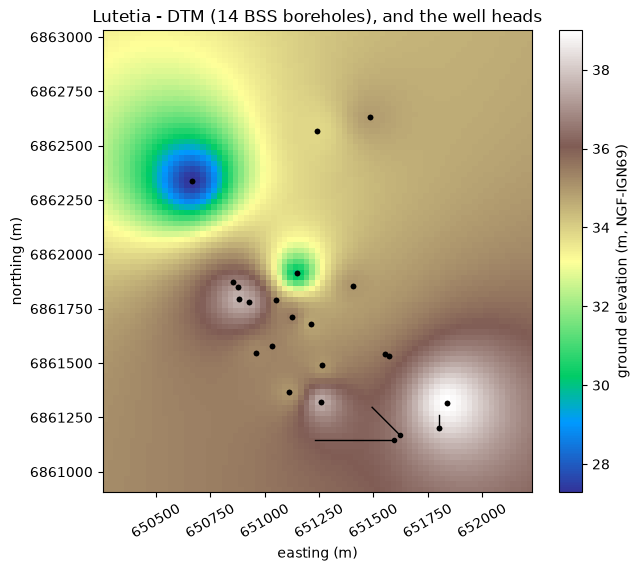

In [8]:
dtm = pkg.find("Grid2dRepresentation", "DTM")[0]
grid = geometry_of(pkg, dtm.uri, "projected")["patches"][0]
nodes = grid["points"].reshape(grid["slowest"], grid["fastest"], 3)

fig, ax = plt.subplots(figsize=(7, 6))
shaded = ax.pcolormesh(nodes[..., 0], nodes[..., 1], nodes[..., 2], cmap="terrain", shading="auto")
fig.colorbar(shaded, ax=ax, label="ground elevation (m, NGF-IGN69)")

for well in pkg.find("WellboreTrajectoryRepresentation"):
    for patch in geometry_of(pkg, well.uri, "projected")["patches"]:
        xyz = patch["points"].reshape(-1, 3)
        ax.plot(xyz[:, 0], xyz[:, 1], "k-", lw=1)
        ax.plot(xyz[0, 0], xyz[0, 1], "ko", ms=3)

ax.set_title(f"{dtm.title}, and the well heads")
ax.set_xlabel("easting (m)")
ax.set_ylabel("northing (m)")
ax.ticklabel_format(useOffset=False, style="plain")
ax.tick_params(axis="x", labelrotation=30)
ax.set_aspect("equal")
plt.show()

## Next

- [03 - Is this package valid?](03-is-this-package-valid.ipynb): judging a package against the
  schema and the rules of the standard.
- [04 - A package from nothing](04-a-package-from-nothing.ipynb): writing one.